# Week 4 · Part E — The written justification (one page)
**Data Visualization (CDB601220)**

This notebook writes the one-page justification **from the numbers the other notebooks computed**, so no figure in the text is typed by hand. It produces:

- `outputs/partE_justification.pdf` — **exactly one page** (the notebook checks and shrinks the font until it fits)
- `outputs/partE_justification.md` — the same text, editable
- `outputs/partE_appendix_28day.png` — the 28-day version the ethics clause refers to

> **How to run:** run *Restart & Run All* in `week4/assignments/`. If `outputs/partB_results.json` or `outputs/partD_results.json` do not exist yet, the first cell runs Parts B and D for you.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

HERE = Path.cwd()                      # run the notebook from week4/assignments
DATA = HERE / "data"
OUT  = HERE / "outputs"; OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(HERE))

import tslib as T                      # Week 4 toolkit (imports Week 3's vizlib)
from tslib import PALETTE, style_defaults, save_fig
style_defaults()
BLUE, ORANGE, GREEN = PALETTE["series"]
PINK, GREY, INK = PALETTE["series_4th"], PALETTE["muted"], PALETTE["ink"]
SOFT = PALETTE["ink_soft"]
SRC = "Source: CDB601220 Week 4 synthetic course data (Superior University Lahore)."

import textwrap
import w4_clean as W
from nbclient import NotebookClient
import nbformat

def ensure(nb_name, needed):
    """Run another notebook if the file it writes is missing."""
    if not (OUT / needed).exists():
        print(f"{needed} missing - executing {nb_name} first ...")
        nb = nbformat.read(HERE / nb_name, 4)
        NotebookClient(nb, timeout=900, kernel_name="python3", resources={"metadata": {"path": str(HERE)}}).execute()
ensure("partB_windows.ipynb", "partB_results.json")
ensure("partD_figure.ipynb", "partD_results.json")
RB = json.loads((OUT / "partB_results.json").read_text())
RD = json.loads((OUT / "partD_results.json").read_text())
L = {l["fault"]: l for l in RD["cleaning_logs"]}
CL = {l["fault"]: l for l in RD["catalogue_logs"]}
print("loaded:", list(RB), "|", list(RD))

loaded: ['B1', 'B2', 'B3', 'B4', 'B5'] | ['cleaning_logs', 'catalogue_logs', 'figure_numbers', 'shares', 'mixed_parse_damage']


## Numbers the text needs (all computed here)

total sessions (sentinel as NaN): 12,010,834 -> 11,727,160 after dropping duplicates (-2.36%)
imputed sentinel hours add 280,239 sessions = 2.33% of the daily total
Wearables share: 10.13% -> 9.35%   Audio: 14.86% -> 14.99%
  2024-04 -> 2024-12: 7-day +12,786   28-day +13,217   same direction: True
  2024-12 -> 2025-05: 7-day -5,536   28-day -5,996   same direction: True
  2025-05 -> 2025-08: 7-day +5,482   28-day +5,444   same direction: True
correlation of the 7-day and 28-day smoothed lines: 0.958


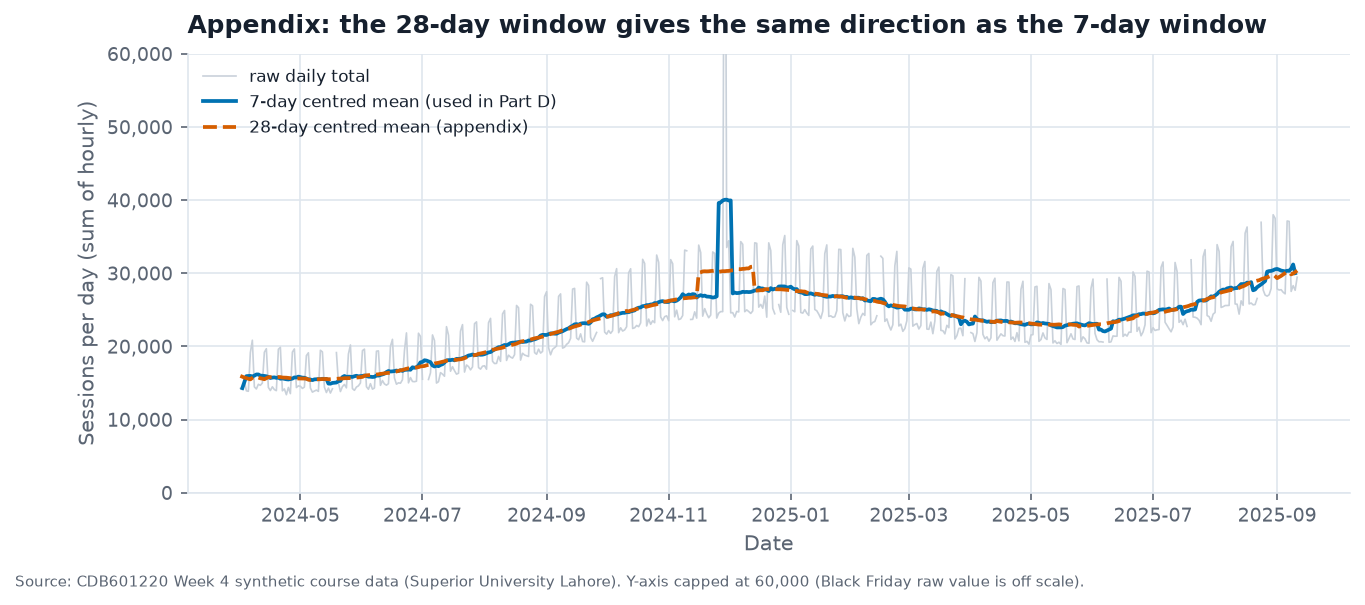

In [2]:
# ---- sessions: what removing the duplicates did to the totals
raw = pd.read_csv(DATA / "sessions_hourly.csv")
ts, _ = W.parse_timestamps(raw)
d0 = raw.drop(columns="ts").set_index(pd.DatetimeIndex(ts, name="ts")).sort_index()
d0["sessions"] = d0.sessions.where(d0.sessions != -1)                  # sentinel -> NaN so it does not distort sums
tot_before = float(d0.sessions.sum())
d1 = d0[~d0.index.duplicated(keep="first")]
tot_after = float(d1.sessions.sum())
dup_move = (tot_after / tot_before - 1) * 100
imputed_total = L["sentinel hours (fill)"]["sessions_filled_total"]
daily = pd.read_csv(OUT / "sessions_daily_clean.csv", index_col=0, parse_dates=True).sessions
imputed_share = imputed_total / float(daily.sum()) * 100
print(f"total sessions (sentinel as NaN): {tot_before:,.0f} -> {tot_after:,.0f} after dropping duplicates ({dup_move:+.2f}%)")
print(f"imputed sentinel hours add {imputed_total:,.0f} sessions = {imputed_share:.2f}% of the daily total")

# ---- catalogue: how the duplicate SKU moved the shares
c0 = pd.read_csv(DATA / "revenue_catalogue.csv")
sh_raw = c0.groupby("subcategory").net_revenue_pkr_m.sum(); sh_raw = sh_raw / sh_raw.sum() * 100
sh_clean = pd.Series(RD["shares"])
wear_raw, wear_clean = float(sh_raw["Wearables"]), float(sh_clean["Wearables"])
audio_raw, audio_clean = float(sh_raw["Audio"]), float(sh_clean["Audio"])
print(f"Wearables share: {wear_raw:.2f}% -> {wear_clean:.2f}%   Audio: {audio_raw:.2f}% -> {audio_clean:.2f}%")

# ---- ethics clause: does a 28-day window change the direction of the story?
s = daily
r7  = s.rolling(7,  center=True, min_periods=5).mean()
r28 = s.rolling(28, center=True, min_periods=14).mean()
mm = lambda r: r.groupby(r.index.to_period("M")).mean()
m7, m28 = mm(r7), mm(r28)
checkpoints = [("2024-04", "2024-12"), ("2024-12", "2025-05"), ("2025-05", "2025-08")]
agree = []
for a, b in checkpoints:
    d7 = np.sign(m7[b] - m7[a]); d28 = np.sign(m28[b] - m28[a]); agree.append(bool(d7 == d28))
    print(f"  {a} -> {b}: 7-day {m7[b]-m7[a]:+,.0f}   28-day {m28[b]-m28[a]:+,.0f}   same direction: {d7 == d28}")
assert all(agree), "the 28-day version changes the direction - the third sentence of the ethics clause would be false; do not use it"
corr = float(r7.corr(r28))
print(f"correlation of the 7-day and 28-day smoothed lines: {corr:.3f}")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(s.index, s, color="#C9D1DA", linewidth=0.8, label="raw daily total")
ax.plot(r7.index, r7, color=BLUE, linewidth=1.8, label="7-day centred mean (used in Part D)")
ax.plot(r28.index, r28, color=ORANGE, linewidth=1.8, linestyle="--", label="28-day centred mean (appendix)")
ax.set_ylim(0, 60000); ax.legend(fontsize=8, loc="upper left")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Appendix: the 28-day window gives the same direction as the 7-day window")
ax.set_xlabel("Date"); ax.set_ylabel("Sessions per day (sum of hourly)")
save_fig(fig, OUT / "partE_appendix_28day.png", note=SRC + " Y-axis capped at 60,000 (Black Friday raw value is off scale)."); plt.show()

## Compose the page

In [3]:
ftn = RD["figure_numbers"]; dmg = RD["mixed_parse_damage"]
b1 = {r["window"]: r for r in RB["B1"]}
b5 = RB["B5"]
n_dup = L["duplicated hours"]["rows_removed"]; n_sent = L["sentinel -1 in sessions"]["n_sentinel"]
gap = L["days never recorded"]; tail = L["partial final month"]
neg = CL["negative net revenue"]; rolled = CL["levels rolled up"]; dupsku = CL["SKU with two parents (not a tree)"]
ISO_N, SLASH_N = L["mixed timestamp formats"]["n_iso"], L["mixed timestamp formats"]["n_slash"]

SECTIONS = []   # (heading, [paragraph strings])

SECTIONS.append(("1. Per panel: the question, the chart type, the Week 2 channel rule", [
 f"<b>Panel 1 - 'Where is traffic really heading?'</b> A line over time: time on the x axis and sessions on a common aligned scale, i.e. <b>position</b>, the most accurate channel (position &gt; length &gt; angle &gt; area). "
 f"Raw daily totals stay in <b>grey for context</b>; the 7-day rolling mean is the single coloured <b>pop-out</b>, so the eye finds the trajectory, not the weekend rhythm.",
 "<b>Panel 2 - 'When in the week do people visit?'</b> A day-of-week x hour heatmap: two categorical axes give position, magnitude goes to colour lightness. Colour is a weaker channel than position, so it is used for the pattern (where is the dark band?), "
 "not for exact values. One-hue <b>sequential</b> colormap because there is no midpoint (Week 3).",
 f"<b>Panel 3 - 'Where is the mass?'</b> A treemap: containment shows category -&gt; sub-category and <b>area</b> (the 4th-best channel, read to about +/-20%) shows size, so every block carries its value in text. "
 f"One hue per parent category and only 4 parents respect the 4 +/- 1 chunk limit.",
 "<b>Panel 4 - 'By how much?'</b> The same eight numbers as sorted horizontal bars: <b>position on a common scale</b>, values printed, rank readable top to bottom. Panels 3 and 4 answer different questions about the same data: where the mass is, and by how much."]))

SECTIONS.append(("2. Every time decision, named and defended", [
 f"<b>Parse.</b> The file mixes {ISO_N:,} ISO timestamps and {SLASH_N:,} slash timestamps. Each is parsed with its own explicit format. The slash format is <b>day-first</b>: its first field reaches {L['mixed timestamp formats']['slash_first_field_max']} while its second never exceeds {L['mixed timestamp formats']['slash_second_field_max']}, so month-first is impossible. "
 f"<font face='Courier'>format='mixed'</font> parses every row without an error but moves {dmg['rows_on_wrong_date']:,} rows to a wrong date and stretches the span from {dmg['span_days_correct']} to {dmg['span_days_mixed']} days. I checked min and max, not just the row count: {dmg['correct_min'][:10]} to {dmg['correct_max'][:10]}.",
 "<b>Resolution and aggregation.</b> Hourly rows are resampled to <b>daily with sum</b>, because sessions are a <b>flow</b> (visits that began during the hour); a flow is never resampled with last(). "
 "The axis says 'Sessions per day (sum of hourly)'. Gaps were counted on the hourly index <i>before</i> resampling, and <font face='Courier'>sum(min_count=24)</font> makes an incomplete day NaN rather than a silent short total or a zero.",
 f"<b>Window.</b> 7 days, centred, requiring at least 5 of 7 days present. It cancels the weekly cycle exactly (Part B.1: removes {b1[7]['variation_removed_pct']}% of raw variation, loses {b1[7]['periods_lost_each_end']} days at each end; 28 days would cost {b1[28]['periods_lost_each_end']}, 91 days {b1[91]['periods_lost_each_end']}). "
 f"<b>Centred, not trailing</b>, because this is a retrospective Monday review: a centred mean puts turns on the right date, while a trailing mean would report them about half a window (3 days) late. A live dashboard would need the trailing version and a caption saying so.",
 "<b>Ethics clause.</b> The window was fixed at 7 days before plotting, because the cycle being removed is weekly (Part B.1). "
 "The series is shown from its first recorded day (1 April 2024); no start date was selected. "
 f"A 28-day version is in the appendix and does not change the direction (the 7- and 28-day lines correlate {corr:.2f}). "
 f"Part B.5 shows why this matters: on the same series {b5['rising']} of 60 start-and-window combinations rise and {b5['falling']} fall. "
 "Symmetry test: I would have kept the same 7-day window if it had weakened my conclusion, because the weekly cycle, not the picture, sets it."]))

SECTIONS.append(("3. Every row removed (rule, count, what moved)", []))
ROWS = [
 ["Duplicate hours", "keep first row per timestamp; every pair verified value-identical", f"{n_dup} rows (12,670 -> {12670 - n_dup:,})", f"total sessions {dup_move:+.2f}%"],
 ["Sentinel sessions = -1", "set to NaN; daily totals refilled with same weekday-hour median, flagged", "0 rows removed; %d hours refilled" % n_sent, f"adds {imputed_share:.2f}% to daily total; excluded from heatmap"],
 ["Days never recorded", "left as gaps (NaN), never zero-filled", f"0 rows; {gap['n_gap_days']} days / {gap['n_missing_hours']} hours absent", "line breaks at 13 places"],
 [f"Partial month ({tail['tail_month']})", "kept, shaded and labelled partial; never compared as a total", f"0 rows; {tail['days_present']} of {tail['days_in_month']} days", "excluded from monthly-median statements"],
 [f"Duplicate SKU ({dupsku['skus'][0]})", "keep the copy whose sku_name prefix matches its sub-category", f"{dupsku['rows_removed']} row (345 -> 344)", f"Wearables share {wear_raw:.2f}% -> {wear_clean:.2f}%; Audio {audio_raw:.2f}% -> {audio_clean:.2f}%"],
 ["Negative net revenue", "never drawn as area; netted inside sub-category totals and reported", f"0 rows; {neg['n_negative_skus']} SKUs, {neg['sum_negative_pkr_m']:.2f}m in total", "all 8 sub-category totals stay positive"],
]

SECTIONS.append(("4. Every level rolled up", [
 f"<b>No 'Other' bucket was needed:</b> 0 categories folded, value 0m, because the smallest sub-category ({ftn['smallest'][0]}) is still {ftn['smallest'][1]:.1f}% of the total. "
 f"The depth was cut at <b>sub-category</b>: {rolled['n_skus_in']} SKUs were summed into {rolled['n_subcategories']} sub-categories (total net revenue {rolled['total_net_pkr_m']:,.1f}m), because 344 blocks would be unreadable. "
 "Tree checks passed: every sub-category has exactly one parent and the children sum to their parents. "
 "Self-check against shares_eight.csv: every sub-category share is within 0.3 percentage points. In Panel 2, 168 weekday-hour cells are shown unrolled."]))

HEAD = "Week 4 - Part E: Justification of the e-commerce review figure"
SUB = "CDB601220 Data Visualization. All data are synthetic course data (Superior University Lahore), not findings about a real business."

# ---------- markdown version
md_lines = [f"# {HEAD}", f"*{SUB}*", ""]
import re
strip = lambda t: re.sub(r"<[^>]+>", "", t).replace("&gt;", ">").replace("&amp;", "&")
for h, ps in SECTIONS:
    md_lines.append(f"## {h}")
    if h.startswith("3."):
        md_lines += ["| Item | Rule | Count | What moved |", "|---|---|---|---|"] + ["| " + " | ".join(r) + " |" for r in ROWS]
    for p in ps: md_lines += [strip(p), ""]
(OUT / "partE_justification.md").write_text("\n".join(md_lines))
print("wrote partE_justification.md (", len(" ".join(md_lines).split()), "words )")

wrote partE_justification.md ( 874 words )


In [6]:
# ---------- one-page PDF with reportlab; shrink the font until it is exactly one page
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.units import cm
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle

def build_pdf(path, fs):
    st_body = ParagraphStyle("b", fontName="Helvetica", fontSize=fs, leading=fs * 1.22, spaceAfter=fs * 0.35)
    st_h = ParagraphStyle("h", fontName="Helvetica-Bold", fontSize=fs + 1.2, leading=(fs + 1.2) * 1.2, spaceBefore=fs * 0.5, spaceAfter=fs * 0.3, textColor=colors.HexColor("#0072B2"))
    st_t = ParagraphStyle("t", fontName="Helvetica-Bold", fontSize=fs + 4, leading=(fs + 4) * 1.15, spaceAfter=2)
    st_s = ParagraphStyle("s", fontName="Helvetica-Oblique", fontSize=fs - 0.8, leading=(fs - 0.8) * 1.2, textColor=colors.HexColor("#5B6573"), spaceAfter=fs * 0.4)
    cell = ParagraphStyle("c", fontName="Helvetica", fontSize=fs - 0.9, leading=(fs - 0.9) * 1.15)
    cellb = ParagraphStyle("cb", parent=cell, fontName="Helvetica-Bold")
    story = [Paragraph(HEAD, st_t), Paragraph(SUB, st_s)]
    for h, ps in SECTIONS:
        story.append(Paragraph(h, st_h))
        if h.startswith("3."):
            data = [[Paragraph(x, cellb) for x in ("Item", "Rule", "Count", "What moved")]] + [[Paragraph(x.replace("&", "&amp;"), cell) for x in r] for r in ROWS]
            tb = Table(data, colWidths=[3.1 * cm, 6.1 * cm, 4.2 * cm, 4.4 * cm], repeatRows=1)
            tb.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), 0.3, colors.HexColor("#C9D1DA")), ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#EEF2F6")),
                                    ("VALIGN", (0, 0), (-1, -1), "TOP"), ("TOPPADDING", (0, 0), (-1, -1), 1.2), ("BOTTOMPADDING", (0, 0), (-1, -1), 1.2)]))
            story += [tb, Spacer(1, 3)]
        for p in ps: story.append(Paragraph(p, st_body))
    pages = []
    class Count(SimpleDocTemplate):
        def afterPage(self): pages.append(1)
    doc = Count(str(path), pagesize=A4, leftMargin=1.5 * cm, rightMargin=1.5 * cm, topMargin=1.2 * cm, bottomMargin=1.1 * cm,
                title="Week 4 Part E - Justification", author="CDB601220")
    doc.build(story)
    return len(pages)

PDF = OUT / "partE_justification.pdf"
for fs in (8.6, 8.4, 8.2, 8.0, 7.8, 7.6, 7.4, 7.2, 7.0, 6.8):
    n = build_pdf(PDF, fs)
    print(f"font {fs}pt -> {n} page(s)")
    if n == 1: break
assert n == 1, "could not fit on one page - shorten the text"
print("saved", PDF, "at", fs, "pt, exactly one page")

font 8.6pt -> 1 page(s)
saved c:\Users\Nas Graphy\Downloads\Data-Visualization\Week 4\outputs\partE_justification.pdf at 8.6 pt, exactly one page


In [5]:
display(Markdown((OUT / "partE_justification.md").read_text()))

# Week 4 - Part E: Justification of the e-commerce review figure
*CDB601220 Data Visualization. All data are synthetic course data (Superior University Lahore), not findings about a real business.*

## 1. Per panel: the question, the chart type, the Week 2 channel rule
Panel 1 - 'Where is traffic really heading?' A line over time: time on the x axis and sessions on a common aligned scale, i.e. position, the most accurate channel (position > length > angle > area). Raw daily totals stay in grey for context; the 7-day rolling mean is the single coloured pop-out, so the eye finds the trajectory, not the weekend rhythm.

Panel 2 - 'When in the week do people visit?' A day-of-week x hour heatmap: two categorical axes give position, magnitude goes to colour lightness. Colour is a weaker channel than position, so it is used for the pattern (where is the dark band?), not for exact values. One-hue sequential colormap because there is no midpoint (Week 3).

Panel 3 - 'Where is the mass?' A treemap: containment shows category -> sub-category and area (the 4th-best channel, read to about +/-20%) shows size, so every block carries its value in text. One hue per parent category and only 4 parents respect the 4 +/- 1 chunk limit.

Panel 4 - 'By how much?' The same eight numbers as sorted horizontal bars: position on a common scale, values printed, rank readable top to bottom. Panels 3 and 4 answer different questions about the same data: where the mass is, and by how much.

## 2. Every time decision, named and defended
Parse. The file mixes 9,019 ISO timestamps and 3,651 slash timestamps. Each is parsed with its own explicit format. The slash format is day-first: its first field reaches 31 while its second never exceeds 12, so month-first is impossible. format='mixed' parses every row without an error but moves 1,382 rows to a wrong date and stretches the span from 528 to 704 days. I checked min and max, not just the row count: 2024-04-01 to 2025-09-11.

Resolution and aggregation. Hourly rows are resampled to daily with sum, because sessions are a flow (visits that began during the hour); a flow is never resampled with last(). The axis says 'Sessions per day (sum of hourly)'. Gaps were counted on the hourly index before resampling, and sum(min_count=24) makes an incomplete day NaN rather than a silent short total or a zero.

Window. 7 days, centred, requiring at least 5 of 7 days present. It cancels the weekly cycle exactly (Part B.1: removes 31.7% of raw variation, loses 3 days at each end; 28 days would cost 14, 91 days 45). Centred, not trailing, because this is a retrospective Monday review: a centred mean puts turns on the right date, while a trailing mean would report them about half a window (3 days) late. A live dashboard would need the trailing version and a caption saying so.

Ethics clause. The window was fixed at 7 days before plotting, because the cycle being removed is weekly (Part B.1). The series is shown from its first recorded day (1 April 2024); no start date was selected. A 28-day version is in the appendix and does not change the direction (the 7- and 28-day lines correlate 0.96). Part B.5 shows why this matters: on the same series 34 of 60 start-and-window combinations rise and 26 fall. Symmetry test: I would have kept the same 7-day window if it had weakened my conclusion, because the weekly cycle, not the picture, sets it.

## 3. Every row removed (rule, count, what moved)
| Item | Rule | Count | What moved |
|---|---|---|---|
| Duplicate hours | keep first row per timestamp; every pair verified value-identical | 286 rows (12,670 -> 12,384) | total sessions -2.36% |
| Sentinel sessions = -1 | set to NaN; daily totals refilled with same weekday-hour median, flagged | 0 rows removed; 287 hours refilled | adds 2.33% to daily total; excluded from heatmap |
| Days never recorded | left as gaps (NaN), never zero-filled | 0 rows; 13 days / 312 hours absent | line breaks at 13 places |
| Partial month (2025-09) | kept, shaded and labelled partial; never compared as a total | 0 rows; 11 of 30 days | excluded from monthly-median statements |
| Duplicate SKU (SKU-0127) | keep the copy whose sku_name prefix matches its sub-category | 1 row (345 -> 344) | Wearables share 10.13% -> 9.35%; Audio 14.86% -> 14.99% |
| Negative net revenue | never drawn as area; netted inside sub-category totals and reported | 0 rows; 7 SKUs, -1.07m in total | all 8 sub-category totals stay positive |
## 4. Every level rolled up
No 'Other' bucket was needed: 0 categories folded, value 0m, because the smallest sub-category (Drones) is still 2.4% of the total. The depth was cut at sub-category: 344 SKUs were summed into 8 sub-categories (total net revenue 1,711.4m), because 344 blocks would be unreadable. Tree checks passed: every sub-category has exactly one parent and the children sum to their parents. Self-check against shares_eight.csv: every sub-category share is within 0.3 percentage points. In Panel 2, 168 weekday-hour cells are shown unrolled.
